# Projet SDP – Jalon 3 : apprentissage MR-Sort face à un agent malicieux
A transmet à B des objets classés par un vrai modèle $M_A$. Pour chaque donnée de A, un agent malicieux ajoute une fausse donnée. B reçoit le mélange et cherche à retrouver $M_A$.

Code : `brouillage.py` (attaques, stratégie de B, expérience) et `run_brouillage.py` (expériences). Les briques d'apprentissage viennent du jalon 2 (`mrsort_lincs.py`, `two_mrsort.py`).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from brouillage import ATTAQUES, attaque_frontiere, random_model, classify
res = pd.read_csv('results/brouillage.csv')
cols = ['fid_plafond', 'fid_un_modele', 'fid_confiance_seule', 'fid_deux_modeles', 'fid_deux_modeles_meilleur', 'purete_segment_A']

## Protocole
- $M_A$ aléatoire (6 critères, 3 classes), A envoie 300 objets uniformes sur $[0,1]^6$ classés par $M_A$ ; l'agent malicieux en ajoute 300.
- B compare : **un seul MR-Sort** appris avec lincs sur tout ce qu'il reçoit ; **deux MR-Sort** appris avec l'heuristique inv-2-MR-Sort du jalon 2, dont il garde celui qui explique le mieux 20 **objets de confiance** (sûrement envoyés par A) ; et, pour référence, un MR-Sort appris sur ces 20 objets seuls.
- *fid* = proportion de 5000 objets de test classés comme par $M_A$ (qualité du jalon 1). *plafond* = MR-Sort appris sur les seules données de A. *meilleur* = le meilleur des deux modèles (choix idéal). *pureté* = part de vraies données dans le segment retenu par B.
- Pourquoi des objets de confiance : avec autant de vraies que de fausses données, les deux segments jouent des rôles symétriques. Sans information en plus, B retrouve deux modèles mais ne peut pas savoir lequel vient de A.

## Partie 1 – Agent basique (MR-Sort aléatoire)

In [2]:
res[res.attaque.isin(['aucune', 'modele_aleatoire'])].groupby('attaque', sort=False)[cols].mean().round(3)

,fid_plafond,fid_un_modele,fid_confiance_seule,fid_deux_modeles,fid_deux_modeles_meilleur,purete_segment_A
attaque,,,,,,
aucune,0.971,0.972,0.659,NaN,NaN,NaN
modele_aleatoire,0.972,0.631,0.643,0.909,0.909,0.802


## Partie 2 – Stratégies de brouillage
- `etiquettes_aleatoires` : objets uniformes, classe au hasard.
- `frontiere_d` : l'agent prend $M_E$ = $M_A$ avec les frontières relevées de $d$, et n'envoie que des objets où $M_E$ et $M_A$ ne sont pas d'accord (juste au-dessus des frontières de $M_A$, avec la classe inférieure).
- `copies_contradictoires` : chaque objet de A est recopié (à un léger bruit près) avec une classe voisine.

In [3]:
ordre = ['aucune', 'modele_aleatoire', 'etiquettes_aleatoires', 'frontiere_0.05', 'frontiere_0.10', 'frontiere_0.20', 'copies_contradictoires']
g = res.groupby('attaque')[cols].mean().reindex(ordre)
g.round(3)

,fid_plafond,fid_un_modele,fid_confiance_seule,fid_deux_modeles,fid_deux_modeles_meilleur,purete_segment_A
attaque,,,,,,
aucune,0.971,0.972,0.659,NaN,NaN,NaN
modele_aleatoire,0.972,0.631,0.643,0.909,0.909,0.802
etiquettes_aleatoires,0.971,0.816,0.659,0.554,0.568,0.560
frontiere_0.05,0.971,0.806,0.659,0.708,0.708,0.543
frontiere_0.10,0.974,0.685,0.659,0.668,0.668,0.690
frontiere_0.20,0.971,0.577,0.659,0.730,0.761,0.936
copies_contradictoires,0.974,0.536,0.659,0.536,0.545,0.570


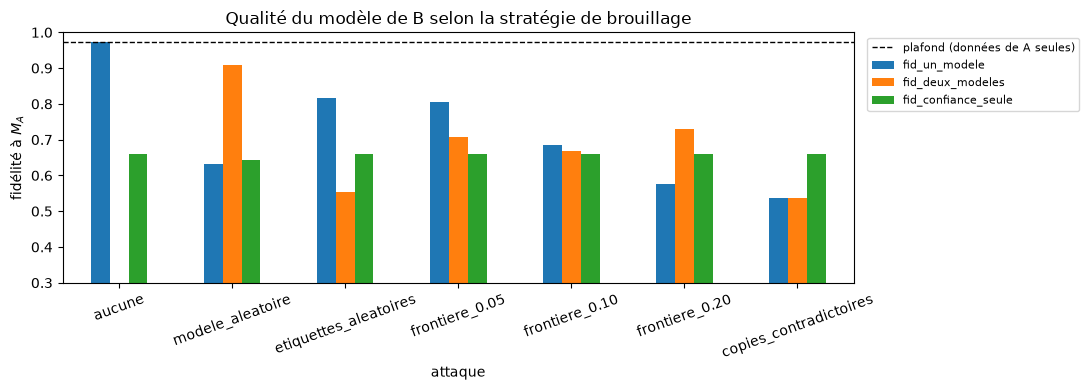

In [4]:
ax = g[['fid_un_modele', 'fid_deux_modeles', 'fid_confiance_seule']].plot.bar(figsize=(11, 4), rot=20)
ax.axhline(g['fid_plafond'].mean(), color='k', ls='--', lw=1, label='plafond (données de A seules)')
ax.set_ylabel('fidélité à $M_A$'); ax.set_ylim(0.3, 1)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
ax.set_title('Qualité du modèle de B selon la stratégie de brouillage'); plt.tight_layout()

### Pourquoi l'attaque près de la frontière est efficace
Sur un exemple à 2 critères : les fausses données (rouge) sont toutes dans la bande située juste au-dessus des frontières de $M_A$. Ailleurs, $M_E$ et $M_A$ donnent la même classe : rien ne permet de séparer les deux sources.

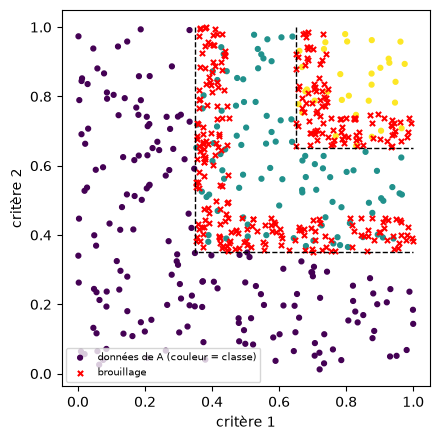

In [5]:
rng = np.random.default_rng(3)
M = {'b': np.array([[0.35, 0.35], [0.65, 0.65]]), 'w': np.array([0.5, 0.5]), 'lam': 0.75}
XA = rng.uniform(0, 1, (300, 2)); yA = classify(XA, M)
XE, yE = attaque_frontiere(XA, yA, M, 3, rng, decalage=0.1)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(*XA.T, c=yA, cmap='viridis', s=12, label='données de A (couleur = classe)')
ax.scatter(*XE.T, c='red', marker='x', s=14, label='brouillage')
for bh in M['b']:
    ax.plot([bh[0], bh[0], 1], [1, bh[1], bh[1]], 'k--', lw=1)
ax.set_xlabel('critère 1'); ax.set_ylabel('critère 2'); ax.legend(fontsize=7, loc='lower left')
plt.tight_layout()

## Conclusions
- **Agent basique (partie 1)** : un seul MR-Sort est très dégradé (fidélité 0,63), alors que l'heuristique à deux modèles du jalon 2, avec 20 objets de confiance pour choisir le bon modèle, remonte à 0,91 (plafond 0,97). Le brouillage d'un MR-Sort aléatoire se sépare bien des vraies données.
- **Aucune stratégie de B ne gagne partout.** Contre des étiquettes aléatoires, un seul MR-Sort résiste (0,82) mais l'heuristique à deux modèles s'effondre (0,55) : le bruit ne suit aucun MR-Sort, la partition trouvée n'a pas de sens. B devrait donc d'abord tester s'il y a vraiment deux modèles.
- **Attaque près de la frontière** : avec un petit décalage (0,05 à 0,10), les fausses données sont presque indiscernables des vraies (pureté du segment retenu 0,54 à 0,69) et les deux stratégies de B tombent vers 0,67 à 0,81. Avec un décalage plus grand (0,20), un seul modèle souffre davantage (0,58), mais le brouillage redevient séparable (pureté 0,94) et l'heuristique remonte en partie (0,73).
- **Copies contradictoires (la meilleure attaque trouvée)** : chaque vraie donnée a un double presque identique avec une classe voisine. Les deux stratégies de B tombent à 0,54, **moins bien que s'il n'utilisait que ses 20 objets de confiance (0,66)**. Rien dans les performances ne distingue la vraie donnée de sa copie.
- Limites : 3 à 5 instances par attaque (variance visible, en particulier pour `frontiere_0.20`) ; l'attaque près de la frontière suppose que l'agent connaît $M_A$ (il peut l'estimer à partir des données de A, qu'il intercepte) ; les copies contradictoires supposent qu'il voit les données de A.
- Pistes pour B : choisir entre un modèle, deux modèles et les objets de confiance seuls selon la précision sur les objets de confiance ; détecter les paires d'objets presque identiques de classes différentes et les écarter.